# Alpha Engine — Exploration

Exploration of the data pulled by `eodhd_client`. Run on the shared `py313 (shared)` Jupyter kernel.

In [134]:
import datetime
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import text

from alpha_engine.maintenance import archive_us_equities_tickers
from util.db import get_engine

In [136]:
# RUSSELL 3000- "IWV"
# S&P 500 - "SPY"
# NASDAQ 100 - "QQQ"

end_year = 2001

start_date = f"{end_year - 1}1201"
end_date = f"{end_year}1201"

with get_engine().connect() as conn:  # ~45M rows
    query = text(
        """
        SELECT symbol, exchange, date, [close], adjusted_close, volume
        FROM dbo.us_equities
        WHERE date >= :start_date
            AND date <  :end_date;
        """
    )
    df = pd.read_sql(
        query, conn, parse_dates=["date"], params={"start_date": start_date, "end_date": end_date}
    )

In [137]:
# import json
# from pathlib import Path

# ticker_counts_by_period: dict[str, int] = {}

# with get_engine().connect() as conn:
#     for end_year in range(2000, 2026):
#         start_date = f"{end_year - 1}1201"
#         end_date = f"{end_year}1201"

#         query = text(
#             """
#             SELECT COUNT(DISTINCT CONCAT(symbol, '|', exchange)) AS ticker_count
#             FROM dbo.us_equities
#             WHERE date >= :start_date
#               AND date < :end_date;
#             """
#         )

#         ticker_count = int(
#             pd.read_sql(
#                 query,
#                 conn,
#                 params={"start_date": start_date, "end_date": end_date},
#             ).iloc[0]["ticker_count"]
#         )
#         ticker_counts_by_period[f"{end_year}-12-01"] = ticker_count

# output_path = Path("ticker_counts_by_period.json")
# output_path.write_text(json.dumps(ticker_counts_by_period, indent=2), encoding="utf-8")

# ticker_counts_by_period

## Exploratory Data Analysis

### 1. `#` of tickers per period

In [138]:
# import json
# from pathlib import Path

# ticker_counts_by_period: dict[str, int] = {}

# with get_engine().connect() as conn:
#     for end_year in range(2000, 2026):
#         start_date = f"{end_year - 1}1201"
#         end_date = f"{end_year}1201"

#         query = text(
#             """
#             SELECT COUNT(DISTINCT CONCAT(symbol, '|', exchange)) AS ticker_count
#             FROM dbo.us_equities
#             WHERE date >= :start_date
#               AND date < :end_date;
#             """
#         )

#         ticker_count = int(
#             pd.read_sql(
#                 query,
#                 conn,
#                 params={"start_date": start_date, "end_date": end_date},
#             ).iloc[0]["ticker_count"]
#         )
#         ticker_counts_by_period[f"{end_year}-12-01"] = ticker_count

# output_path = Path("ticker_counts_by_period.json")
# output_path.write_text(json.dumps(ticker_counts_by_period, indent=2), encoding="utf-8")

# ticker_counts_by_period

### 1a. Archive tickers with less than `365d` of history

In [139]:
print(
    f"Starting # of tickers for {end_year - 1}-12-01 until {end_year}-11-30:",
    len(df["symbol"].unique()),
)

Starting # of tickers for 2000-12-01 until 2001-11-30: 7544


In [140]:
# with get_engine().connect() as conn:
#     query = text(
#         """
#         SELECT symbol, exchange, start_date, end_date, delisted
#         FROM dbo.us_equities_ingest_status
#         """
#     )
#     tickers_df = pd.read_sql(query, conn, parse_dates=["start_date", "end_date"])

# tickers_subset_df = tickers_df.loc[
#     ((tickers_df["end_date"] - tickers_df["start_date"]).dt.days < 365)
#     & (tickers_df["end_date"].dt.date < datetime.date(2026, 8, 24))  # end_date - 10 days
# ]

# tickers_subset_df.loc[~tickers_subset_df["delisted"]]

# archive_us_equities_tickers(tickers_subset_df.loc[tickers_subset_df["delisted"]])

### 1b. Analyze the meaning of `_OLD` in ticker names

In [141]:
# with get_engine().connect() as conn:  # ~45M rows
#     query = text(
#         """
#         SELECT *
#         FROM dbo.us_equities_ingest_status
#         """
#     )
#     ticker_df = pd.read_sql(query, conn, parse_dates=["date"])

In [142]:
# ticker_sub1_df = ticker_df.loc[ticker_df["symbol"].str.contains("_OLD")]
# ticker_list = ticker_sub1_df["symbol"].str.replace("_OLD", "").tolist()
# ticker_sub2_df = ticker_df.loc[ticker_df["symbol"].isin(ticker_list)]

# ticker_sub_df = pd.concat([ticker_sub1_df, ticker_sub2_df], ignore_index=True).sort_values(
#     by="symbol"
# )

# e.g. ACH Accendra Health Inc v.s. ACH_OLD Aluminum Corp of China Ltd ADR
# Accendra Health, Inc. trades on the New York Stock Exchange under the new ticker symbol “ACH”,
# effective January 2, 2026.

### 2. Calculate historical `Dollar Volume` - `Russell 3000`
To make your strategy less susceptible to illiquidity traps, extreme volatility, and market manipulation, you need to define a minimum threshold for institutional market access. 

In [143]:
df["dollar_volume"] = df["close"] * df["volume"]

df["dollar_volume"].describe()

count    1.702890e+06
mean     3.315784e+08
std      5.163969e+10
min      0.000000e+00
25%      1.368750e+04
50%      2.244000e+05
75%      3.362938e+06
max      3.994889e+13
Name: dollar_volume, dtype: float64

c:\Users\lott7\.venvs\py313\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


<Axes: xlabel='dollar_volume', ylabel='Count'>

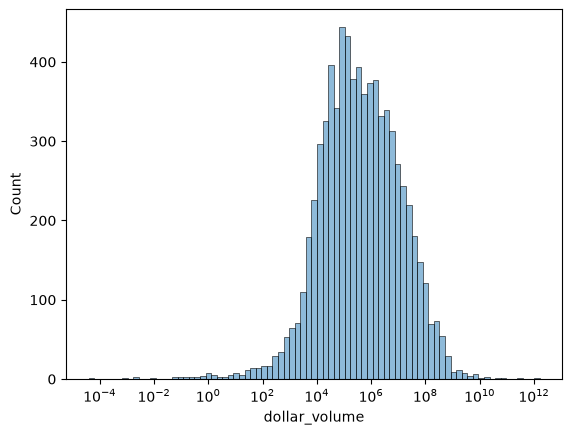

In [144]:
avg_day_volume = df.groupby(["symbol"])["dollar_volume"].agg(np.mean).reset_index()

sns.histplot(data=avg_day_volume, x="dollar_volume", log_scale=True, kde=True)

In [145]:
q = 1 - 2500 / len(avg_day_volume)
threshold = np.quantile(avg_day_volume["dollar_volume"], q)

print(f"Threshold to get the 2,500 stocks with the highes dollar_volume: ${threshold:,.2f}")

Threshold to get the 2,500 stocks with the highes dollar_volume: $1,708,354.11


<Axes: xlabel='dollar_volume', ylabel='Count'>

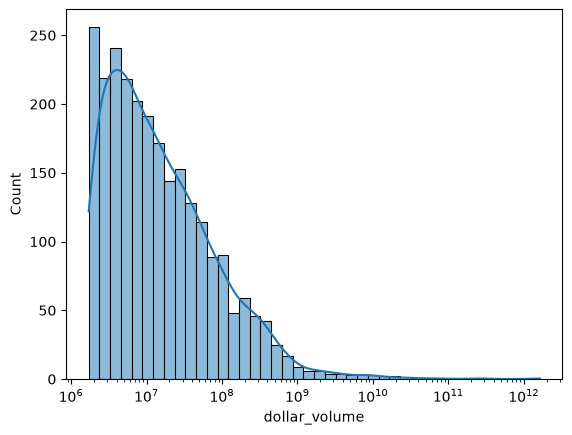

In [146]:
sns.histplot(
    data=avg_day_volume.loc[
        avg_day_volume["dollar_volume"] >= np.quantile(avg_day_volume["dollar_volume"], q=q)
    ],
    x="dollar_volume",
    log_scale=True,
    kde=True,
)